# 02 — Preprocessing, validation splits and ShiftSim (Task 2)

This notebook fixes everything that later notebooks rely on:

1. flag degenerate training images
2. group exact / near duplicates and build the 5 stratified group folds → `data/folds.csv`
3. calibrate **ShiftSim** (the simulation of the test framing used for `val_shift`) → `data/shiftsim_params.json`
4. compare real test images with ShiftSim(train) images side by side
5. adversarial validation (train-vs-test classifier on metadata and on image embeddings) before and after ShiftSim
6. preview the preprocessing and the three augmentation levels
7. benchmark the data loader and the candidate models → expected training times

`data/folds.csv` and `data/shiftsim_params.json` are written **once** and never regenerated (delete them by hand
to start again), so every experiment is scored on the same validation images.

In [1]:
N_JOBS = 8               # processes for the file scan (cached by notebook 01)
CALIB_TRIALS = 300       # random-search trials for the ShiftSim calibration
CALIB_SAMPLE = 8000      # training images used inside each calibration trial
ADV_EMBED = True         # adversarial validation on pretrained image embeddings (uses the GPU, a few minutes)
ADV_EMBED_N = 3000       # images per side for the embedding version
BENCHMARK = True         # loader / model speed benchmarks (a few minutes)
GRID_N = 12
SEED = 42

In [2]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd()))  # the notebooks live in the repo root, next to src/

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

sns.set_theme(style="whitegrid")
pd.set_option("display.precision", 4)
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)

import json
import torch
from PIL import Image
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import StratifiedGroupKFold, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

from src.config import (CLASSES, DEFAULT_SHIFTSIM, FIG_DIR, FOLDS_CSV, N_FOLDS, PRESETS, SHIFTSIM_JSON,
                        get_device, make_config, make_dirs)
from src.data import FaceDataset, get_image_meta, load_test_df, make_loader
from src.engine import benchmark_loader, benchmark_model, predict_logits
from src.models import create_model, get_mean_std
from src.plots import denormalize, savefig, show_grid
from src.transforms import (ShiftSim, build_eval_transform, build_train_transform, calibrate_shiftsim,
                            geometry_distance, geometry_stats)
from src.utils import connected_groups

make_dirs()
meta_tr = get_image_meta("train", N_JOBS)
meta_te = get_image_meta("test", N_JOBS)
for m in (meta_tr, meta_te):
    m["short"] = m[["w", "h"]].min(axis=1)
    m["aspect"] = m["w"] / m["h"]
print(meta_tr.shape, meta_te.shape)

/Users/avathanshubhat/Documents/AUT/Y3S2/ENGE707 - Data Engineering & AI/Kaggle Contest/ENGE707_Kaggle_Competition/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


(63660, 25) (29443, 25)


## 1. Degenerate training images

Rule: shorter side < 8 px, or aspect ratio > 3 or < 1/3. These images are only **flagged** here; the training loop
skips them when `drop_degenerate=True` (the default). Validation folds and the test set keep every image.

degenerate training images: 15 of 63660


,count,share
class,,
CatEye,4,0.0003
CatFace,1,0.0001
CatMouth,5,0.0007
CatNose,5,0.0007
DogEye,0,0.0000
DogFace,0,0.0000
DogMouth,0,0.0000
DogNose,0,0.0000


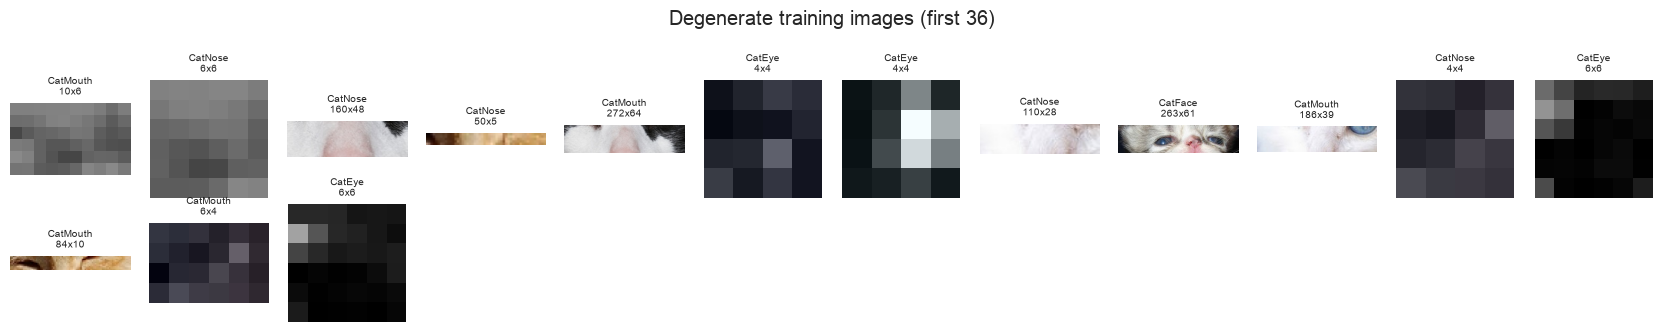

In [3]:
meta_tr["degenerate"] = (meta_tr["short"] < 8) | (meta_tr["aspect"] > 3) | (meta_tr["aspect"] < 1 / 3)
print("degenerate training images:", int(meta_tr["degenerate"].sum()), "of", len(meta_tr))
display(meta_tr.groupby("class")["degenerate"].agg(["sum", "mean"]).reindex(CLASSES)
        .rename(columns={"sum": "count", "mean": "share"}))
d = meta_tr[meta_tr["degenerate"]].head(36)
show_grid(d["path"].tolist(), [f"{c}\n{w}x{h}" for c, w, h in zip(d["class"], d["w"], d["h"])],
          ncols=GRID_N, suptitle="Degenerate training images (first 36)", name="02_degenerate")

> **Observations (to be written by me):**

## 2. Duplicate groups and the 5 folds

Images that are exact duplicates (same MD5) or near duplicates (same dHash) are put in one **group**, so they
always land in the same fold. dHash values shared by more than 5 images are ignored for grouping: those are
mostly flat / tiny images whose hashes collide by chance.

Folds: `StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)`, stratified by class.

Limitation: the eye / nose / mouth crops of one animal photo are not linked to their face crop, so parts of the
same animal can sit in different folds.

In [4]:
dh_size = meta_tr.groupby("dhash")["dhash"].transform("size")
meta_tr["dhash_for_group"] = np.where(dh_size <= 5, meta_tr["dhash"], "unique_" + meta_tr["image_id"])
meta_tr["group"] = connected_groups(meta_tr, ["md5", "dhash_for_group"])
sizes = meta_tr.groupby("group").size()
print(f"{len(meta_tr)} images -> {len(sizes)} groups; groups with >1 image: {(sizes > 1).sum()} "
      f"(covering {sizes[sizes > 1].sum()} images); largest group: {sizes.max()}")

if FOLDS_CSV.exists():
    folds = pd.read_csv(FOLDS_CSV, dtype={"image_id": str})
    print("data/folds.csv already exists - loaded, NOT regenerated")
else:
    sgkf = StratifiedGroupKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)
    meta_tr["fold"] = -1
    for k, (_, val_idx) in enumerate(sgkf.split(meta_tr, meta_tr["class"], meta_tr["group"])):
        meta_tr.loc[meta_tr.index[val_idx], "fold"] = k
    folds = meta_tr[["image_id", "class", "fold", "group", "w", "h", "degenerate"]].sort_values("image_id")
    folds.to_csv(FOLDS_CSV, index=False)
    print("wrote", FOLDS_CSV)

63660 images -> 63617 groups; groups with >1 image: 43 (covering 86 images); largest group: 2
data/folds.csv already exists - loaded, NOT regenerated


In [5]:
check = {
    "every image has a fold": bool((folds["fold"] >= 0).all()) and len(folds) == len(meta_tr),
    "no group is split across folds": bool((folds.groupby("group")["fold"].nunique() == 1).all()),
}
display(pd.Series(check, name="value").to_frame())
display(pd.crosstab(folds["class"], folds["fold"], margins=True).reindex(CLASSES + ["All"]))
display((pd.crosstab(folds["fold"], folds["class"], normalize="index") * 100).round(2))

,value
every image has a fold,True
no group is split across folds,True


fold,0,1,2,3,4,All
class,,,,,,
CatEye,2777,2776,2777,2777,2777,13884
CatFace,1388,1389,1389,1388,1388,6942
CatMouth,1389,1388,1388,1389,1388,6942
CatNose,1388,1389,1388,1388,1389,6942
DogEye,2316,2316,2316,2316,2316,11580
DogFace,1158,1158,1158,1158,1158,5790
DogMouth,1158,1158,1158,1158,1158,5790
DogNose,1158,1158,1158,1158,1158,5790
All,12732,12732,12732,12732,12732,63660


class,CatEye,CatFace,CatMouth,CatNose,DogEye,DogFace,DogMouth,DogNose
fold,,,,,,,,
0,21.81,10.90,10.91,10.90,18.19,9.1,9.1,9.1
1,21.80,10.91,10.90,10.91,18.19,9.1,9.1,9.1
2,21.81,10.91,10.90,10.90,18.19,9.1,9.1,9.1
3,21.81,10.90,10.91,10.90,18.19,9.1,9.1,9.1
4,21.81,10.90,10.90,10.91,18.19,9.1,9.1,9.1


> **Observations (to be written by me):**

## 3. ShiftSim calibration

ShiftSim (see `src/transforms.py`) leaves an image unchanged with probability `p_keep`; otherwise it cuts a random
sub-box (area fraction in [`scale_min`, 1], aspect multiplied by a factor in [1/`aspect_max`, `aspect_max`]) and,
with probability `p_round`, resizes the crop to a size whose sides are multiples of 10 (after shrinking by a factor in
[`shrink_min`, 1]).

Calibration = random search over these five parameters. Each trial applies ShiftSim to the **sizes** of
`CALIB_SAMPLE` training images (no pixels are touched) and measures the L1 distance between `geometry_stats` of the
result and `geometry_stats` of the test set: sum of the absolute differences of the percentage rows + 20 × the relative error of the shorter-side
quantiles (a 10 % size error costs 2 points).
Only unlabelled test image sizes are used.

In [6]:
target = geometry_stats(meta_te["w"], meta_te["h"])
calib_idx = np.random.default_rng(SEED).choice(len(meta_tr), CALIB_SAMPLE, replace=False)
cw, ch = meta_tr["w"].values[calib_idx], meta_tr["h"].values[calib_idx]

if SHIFTSIM_JSON.exists():
    params = json.loads(SHIFTSIM_JSON.read_text())
    print("data/shiftsim_params.json already exists - loaded, NOT recalibrated")
    search = None
else:
    search = calibrate_shiftsim(cw, ch, target, n_trials=CALIB_TRIALS, seed=SEED)
    params = dict(search.iloc[0].drop("distance").to_dict(), seed=SEED)
    SHIFTSIM_JSON.write_text(json.dumps(params, indent=2))
    print("wrote", SHIFTSIM_JSON)
    display(search.head(10).round(3))
print(json.dumps(params, indent=2))

wrote /Users/avathanshubhat/Documents/AUT/Y3S2/ENGE707 - Data Engineering & AI/Kaggle Contest/ENGE707_Kaggle_Competition/data/shiftsim_params.json


,p_keep,scale_min,aspect_max,p_round,shrink_min,distance
0,0.335,0.650,1.140,0.257,0.556,34.488
1,0.376,0.661,1.079,0.088,0.967,34.682
2,0.491,0.789,1.391,0.221,0.851,36.071
3,0.346,0.598,1.087,0.072,0.711,37.227
4,0.366,0.529,1.084,0.132,0.541,37.598
5,0.264,0.636,1.079,0.114,0.779,38.008
6,0.283,0.685,1.072,0.094,0.495,38.248
7,0.468,0.626,1.371,0.028,0.623,38.548
8,0.467,0.478,1.165,0.097,0.498,38.634
9,0.493,0.690,1.274,0.270,0.553,38.643


{
  "p_keep": 0.33451409181662206,
  "scale_min": 0.6501336211569311,
  "aspect_max": 1.1395419643173241,
  "p_round": 0.2572582670805896,
  "shrink_min": 0.5564747148783732,
  "seed": 42
}


Geometry of train, ShiftSim(train) and test on **all** training images. Here ShiftSim uses the image id as its random
key, i.e. exactly the transformation that builds the `val_shift` images. The row "default ShiftSim" uses the
untuned starting values in `src/config.py` for comparison.

In [7]:
sim = ShiftSim(**params)
keys = meta_tr["image_id"].astype(int).values
sw, sh = sim.simulate_sizes(meta_tr["w"].values, meta_tr["h"].values, keys=keys)
dw, dh = ShiftSim(**DEFAULT_SHIFTSIM).simulate_sizes(meta_tr["w"].values, meta_tr["h"].values, keys=keys)

calib = pd.DataFrame({"train": geometry_stats(meta_tr["w"], meta_tr["h"]),
                      "default ShiftSim(train)": geometry_stats(dw, dh),
                      "calibrated ShiftSim(train)": geometry_stats(sw, sh),
                      "test": target})
dist = {c: geometry_distance(calib[c], target) for c in calib.columns}
display(calib.round(2))
display(pd.Series(dist, name="distance to test").round(2).to_frame())
calib.to_csv(FIG_DIR / "02_shiftsim_calibration.csv")

,train,default ShiftSim(train),calibrated ShiftSim(train),test
square %,65.52,37.84,32.49,32.85
odd dimension %,18.91,35.18,41.93,55.01
both multiples of 10 %,13.81,20.02,22.57,21.24
aspect < 0.80 %,4.46,7.06,4.87,7.34
aspect 0.80-0.995 %,5.87,17.36,22.33,18.41
aspect 0.995-1.03 %,67.93,40.10,36.12,38.26
aspect 1.03-1.30 %,1.52,17.62,19.11,16.97
aspect 1.30-1.50 %,19.95,14.21,14.95,14.93
aspect > 1.50 %,0.27,3.65,2.61,4.09
short side p5,30.00,24.00,24.00,28.00


,distance to test
train,147.35
default ShiftSim(train),37.19
calibrated ShiftSim(train),33.34
test,0.00


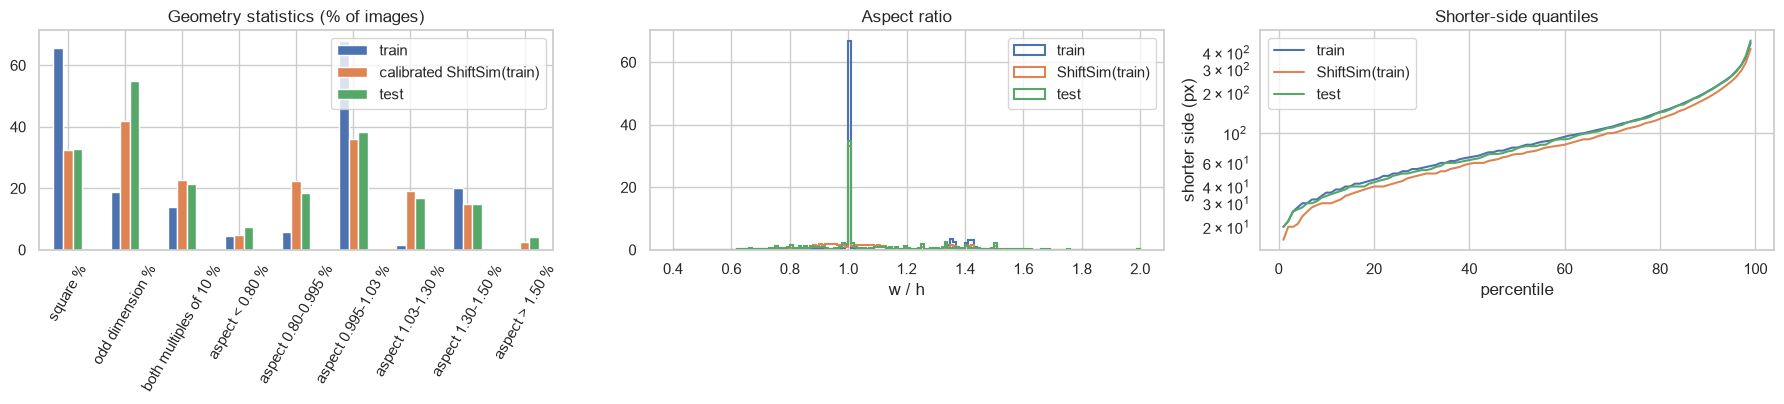

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.2))
pct_rows = [r for r in calib.index if r.endswith("%")]
calib.loc[pct_rows, ["train", "calibrated ShiftSim(train)", "test"]].plot.bar(ax=axes[0])
axes[0].set_title("Geometry statistics (% of images)")
axes[0].tick_params(axis="x", rotation=60)

bins = np.linspace(0.4, 2.0, 161)
for label, ar in [("train", meta_tr["w"] / meta_tr["h"]), ("ShiftSim(train)", sw / sh), ("test", meta_te["aspect"])]:
    axes[1].hist(np.clip(ar, 0.4, 2.0), bins=bins, density=True, histtype="step", lw=1.5, label=label)
axes[1].set_title("Aspect ratio")
axes[1].set_xlabel("w / h")
axes[1].legend()

qs = np.linspace(0.01, 0.99, 99)
for label, short in [("train", meta_tr["short"]), ("ShiftSim(train)", np.minimum(sw, sh)), ("test", meta_te["short"])]:
    axes[2].plot(qs * 100, np.quantile(short, qs), label=label)
axes[2].set_yscale("log")
axes[2].set_xlabel("percentile")
axes[2].set_ylabel("shorter side (px)")
axes[2].set_title("Shorter-side quantiles")
axes[2].legend()
plt.tight_layout()
savefig("02_shiftsim_calibration")
plt.show()

> **Observations (to be written by me):**

## 4. Real test images vs ShiftSim(train)

Top block: random real test images. Bottom block: random training images after ShiftSim (the `val_shift` version).
Then pairs of original / ShiftSim for perturbed training images. Images keep their aspect ratio inside each cell.

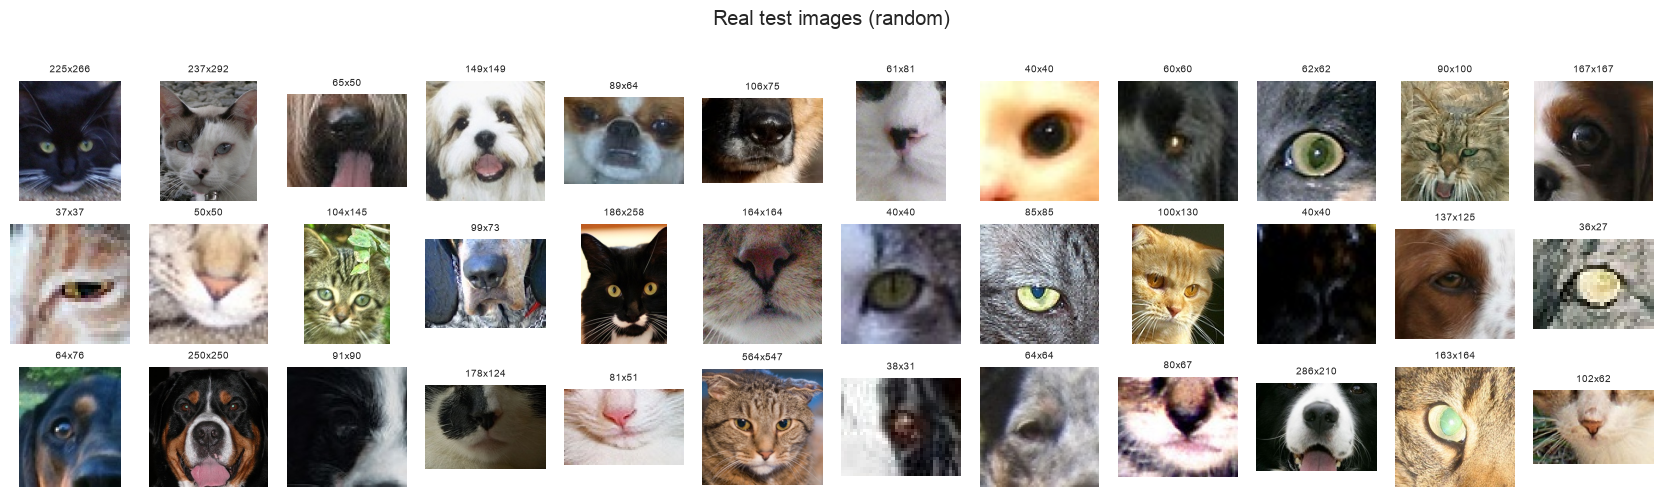

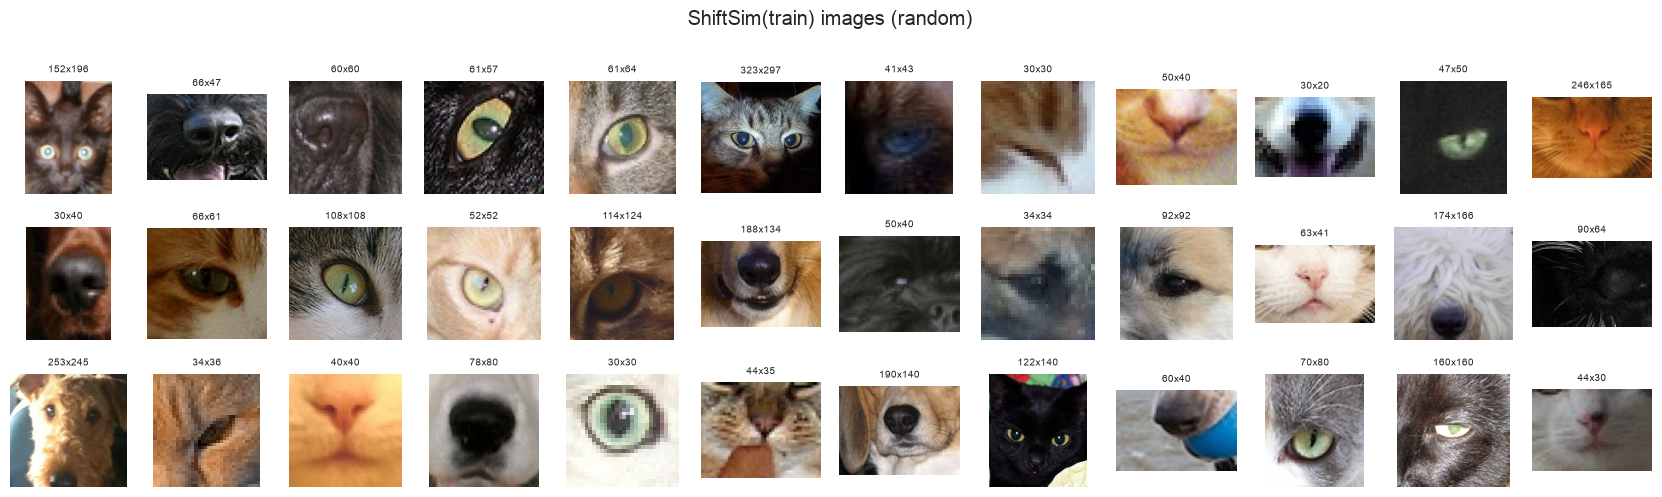

In [9]:
rng = np.random.default_rng(SEED)
s_te = meta_te.sample(36, random_state=SEED)
show_grid(s_te["path"].tolist(), ncols=GRID_N, suptitle="Real test images (random)", name="02_grid_test")

s_tr = meta_tr.sample(36, random_state=SEED + 1)
sim_imgs = [sim(Image.open(p).convert("RGB"), key=int(i)) for p, i in zip(s_tr["path"], s_tr["image_id"])]
show_grid(sim_imgs, ncols=GRID_N, suptitle="ShiftSim(train) images (random)", name="02_grid_shiftsim")

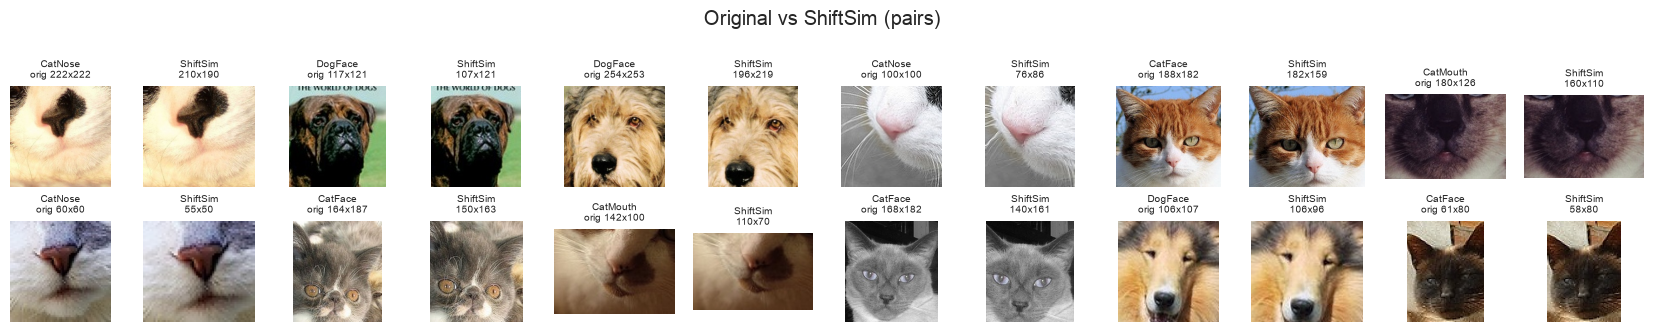

In [10]:
perturbed = meta_tr[(sw != meta_tr["w"].values) | (sh != meta_tr["h"].values)].sample(GRID_N, random_state=SEED)
imgs, titles = [], []
for _, r in perturbed.iterrows():
    orig = Image.open(r["path"]).convert("RGB")
    new = sim(orig, key=int(r["image_id"]))
    imgs += [orig, new]
    titles += [f"{r['class']}\norig {orig.width}x{orig.height}", f"ShiftSim\n{new.width}x{new.height}"]
show_grid(imgs, titles, ncols=GRID_N, suptitle="Original vs ShiftSim (pairs)", name="02_pairs_shiftsim")

> **Observations (to be written by me):**

## 5. Adversarial validation

A classifier is trained to tell **train** images from **test** images (label 0 = train, 1 = test; no class labels
are used). ROC AUC from 5-fold cross-validated predictions: 0.5 = indistinguishable, 1.0 = perfectly separable.
It is run twice: original training images vs test, and ShiftSim(train) vs test.

### 5a. On image metadata
Features: width, height, aspect ratio, log shorter side, odd width, odd height, both sides multiples of 10, square.
Model: `HistGradientBoostingClassifier`. All 29,443 test images vs the same number of random training images.

In [11]:
def meta_features(w, h):
    w, h = np.asarray(w, float), np.asarray(h, float)
    return pd.DataFrame({"w": w, "h": h, "aspect": w / h, "log_short": np.log(np.minimum(w, h)),
                         "odd_w": w % 2, "odd_h": h % 2, "round": ((w % 10 == 0) & (h % 10 == 0)).astype(float),
                         "square": (w == h).astype(float)})

idx = np.random.default_rng(SEED).choice(len(meta_tr), len(meta_te), replace=False)
y_adv = np.r_[np.zeros(len(idx)), np.ones(len(meta_te))]
X_test_meta = meta_features(meta_te["w"], meta_te["h"])
variants = {"original train vs test": meta_features(meta_tr["w"].values[idx], meta_tr["h"].values[idx]),
            "ShiftSim(train) vs test": meta_features(sw[idx], sh[idx])}

adv_rows, adv_probs = [], {}
for name, X_tr in variants.items():
    X = pd.concat([X_tr, X_test_meta], ignore_index=True)
    p = cross_val_predict(HistGradientBoostingClassifier(random_state=SEED), X, y_adv, cv=5, method="predict_proba")[:, 1]
    adv_probs[name] = p
    row = {"comparison": name, "AUC (all features)": roc_auc_score(y_adv, p)}
    for f in X.columns:  # AUC of each single feature, folded so that 0.5 is the minimum
        a = roc_auc_score(y_adv, X[f])
        row[f"AUC {f}"] = max(a, 1 - a)
    adv_rows.append(row)
display(pd.DataFrame(adv_rows).set_index("comparison").round(3).T)

comparison,original train vs test,ShiftSim(train) vs test
AUC (all features),0.894,0.781
AUC w,0.501,0.544
AUC h,0.503,0.542
AUC aspect,0.507,0.506
AUC log_short,0.513,0.539
AUC odd_w,0.641,0.559
AUC odd_h,0.619,0.549
AUC round,0.537,0.506
AUC square,0.664,0.501


Training images the metadata classifier finds most "test-like" (highest predicted P(test)), original sizes.

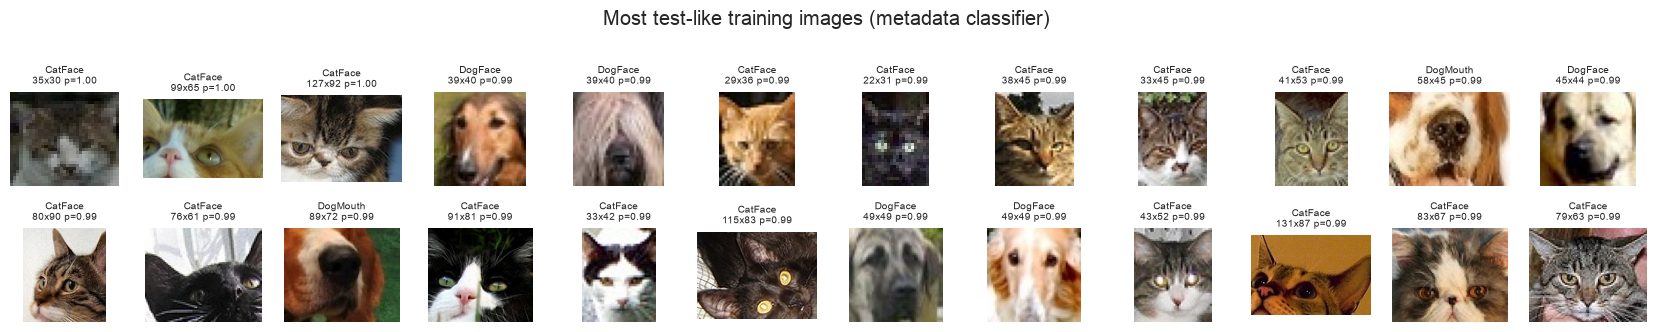

In [12]:
p_tr = adv_probs["original train vs test"][: len(idx)]
order = np.argsort(-p_tr)[:24]
rows = meta_tr.iloc[idx[order]]
show_grid(rows["path"].tolist(), [f"{c}\n{w}x{h} p={pp:.2f}" for c, w, h, pp in zip(rows["class"], rows["w"], rows["h"], p_tr[order])],
          ncols=GRID_N, suptitle="Most test-like training images (metadata classifier)", name="02_most_test_like")

### 5b. On image embeddings
A frozen ImageNet-pretrained EfficientNet-B0 (`efficientnet_b0.ra_in1k`, 128 px, squash resize) turns each image into a
1280-dimensional vector; a standardised logistic regression separates train from test.
`ADV_EMBED_N` random images per side; the same training ids are used in both comparisons.

In [13]:
if ADV_EMBED:
    device = get_device()
    ecfg = make_config("abl_base")
    emb_model = create_model(ecfg, num_classes=0).to(device).eval()  # num_classes=0 -> pooled features
    etf = build_eval_transform(ecfg, *get_mean_std(emb_model))
    tr_s = meta_tr.sample(ADV_EMBED_N, random_state=SEED).assign(label=-1)
    te_s = meta_te.sample(ADV_EMBED_N, random_state=SEED).assign(label=-1)

    def embed(df, shift_sim=None):
        loader = make_loader(FaceDataset(df, etf, shift_sim=shift_sim), 256, num_workers=6)
        return predict_logits(emb_model, loader, device, amp=True, desc="embed")

    E_te, E_tr, E_sim = embed(te_s), embed(tr_s), embed(tr_s, sim)
    y_e = np.r_[np.zeros(ADV_EMBED_N), np.ones(ADV_EMBED_N)]
    clf = make_pipeline(StandardScaler(), LogisticRegression(C=0.1, max_iter=2000))
    emb_auc = {}
    for name, E in [("original train vs test", E_tr), ("ShiftSim(train) vs test", E_sim)]:
        p = cross_val_predict(clf, np.r_[E, E_te], y_e, cv=5, method="predict_proba")[:, 1]
        emb_auc[name] = roc_auc_score(y_e, p)
    display(pd.Series(emb_auc, name="embedding AUC").round(3).to_frame())

embed:   0%|          | 0/12 [00:00<?, ?it/s]

embed:   0%|          | 0/12 [00:00<?, ?it/s]

embed:   0%|          | 0/12 [00:00<?, ?it/s]

,embedding AUC
original train vs test,0.523
ShiftSim(train) vs test,0.538


> **Observations (to be written by me):**

## 6. Preprocessing and augmentation preview

Preprocessing (identical for validation and test): RGB → squash-resize to a square (bicubic, antialiased) →
float in [0, 1] → normalise with the backbone's mean / std. Training augmentation levels (`src/transforms.py`):

* `none` — preprocessing only
* `plain` — resize + horizontal flip + colour jitter
* `shift` — RandomResizedCrop (area 0.6–1.0, aspect 0.6–1.67) + random low resolution (p = 0.3) + flip +
  rotation ≤ 15° (p = 0.3) + colour jitter + greyscale (p = 0.05) + blur (p = 0.2) + JPEG quality 40–95 (p = 0.3)

The first column is the original image; the others are 7 random draws of the transform, shown after de-normalising.

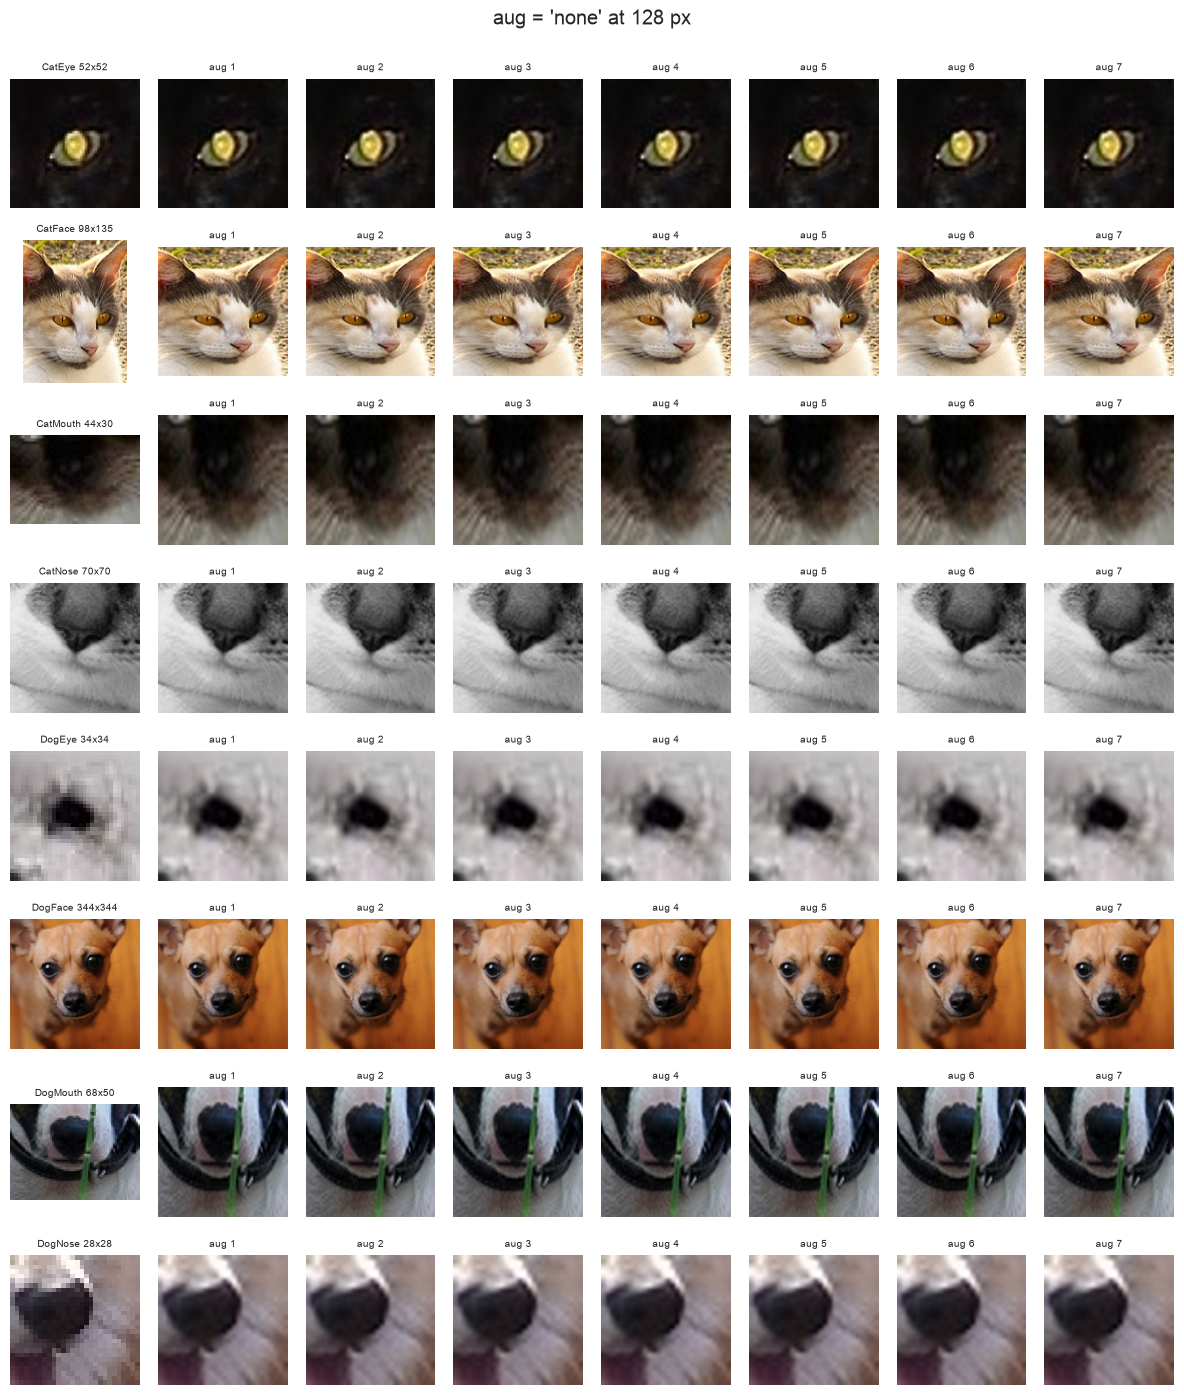

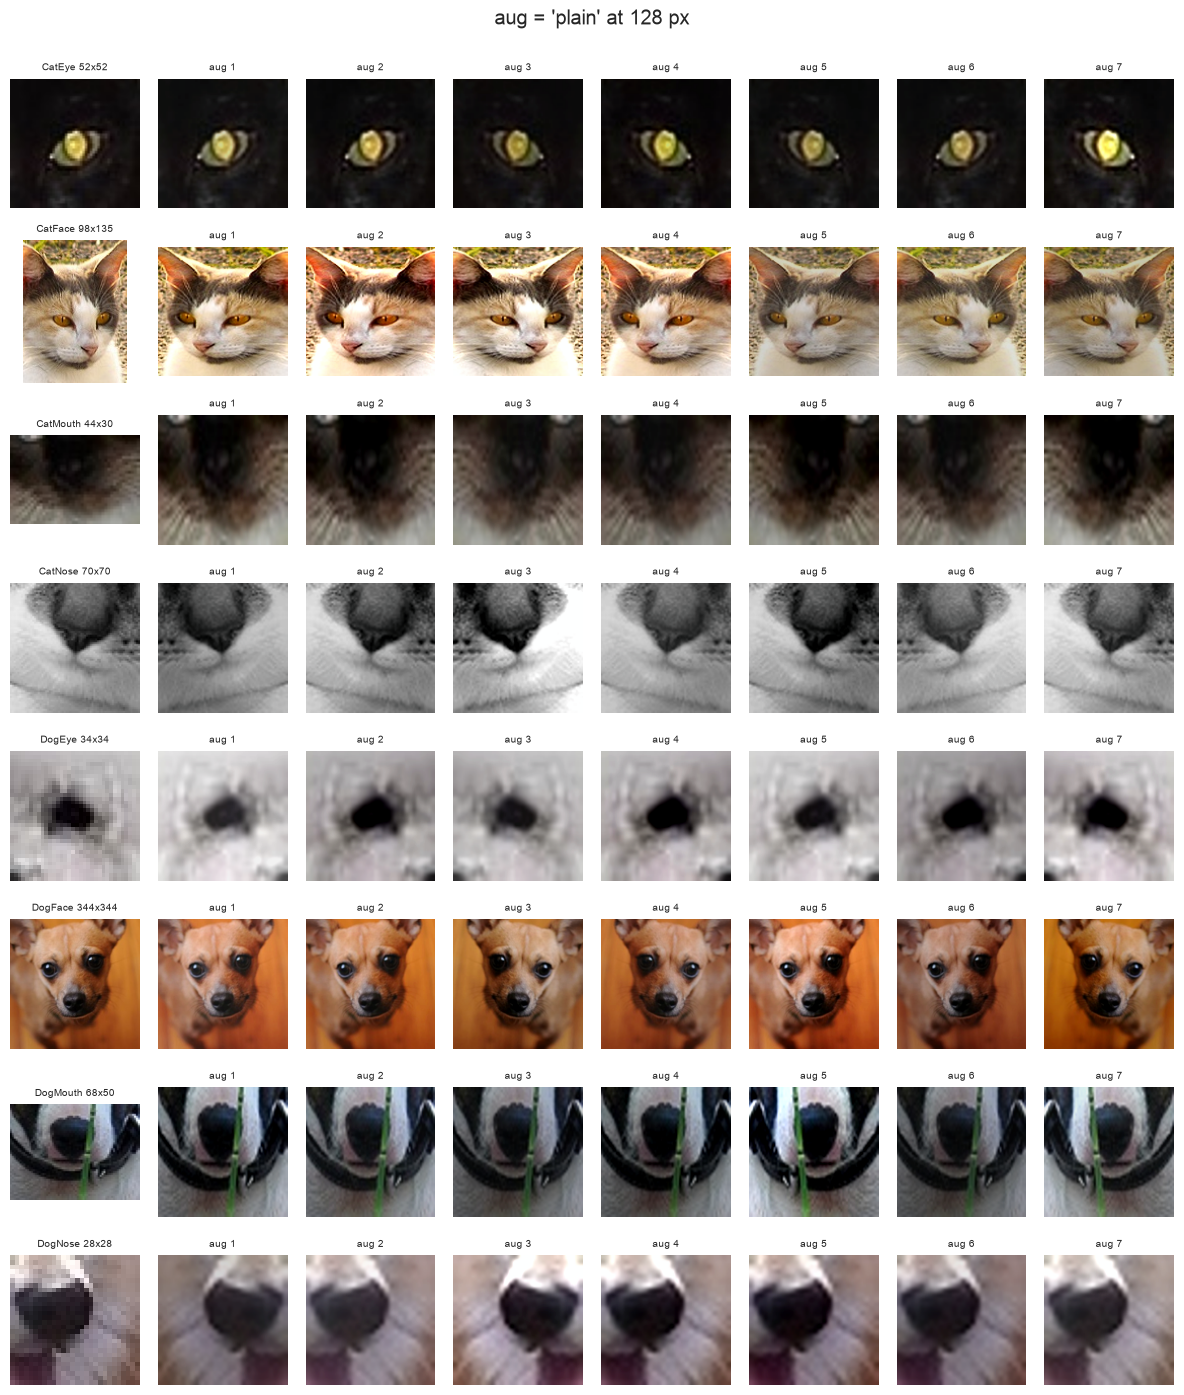

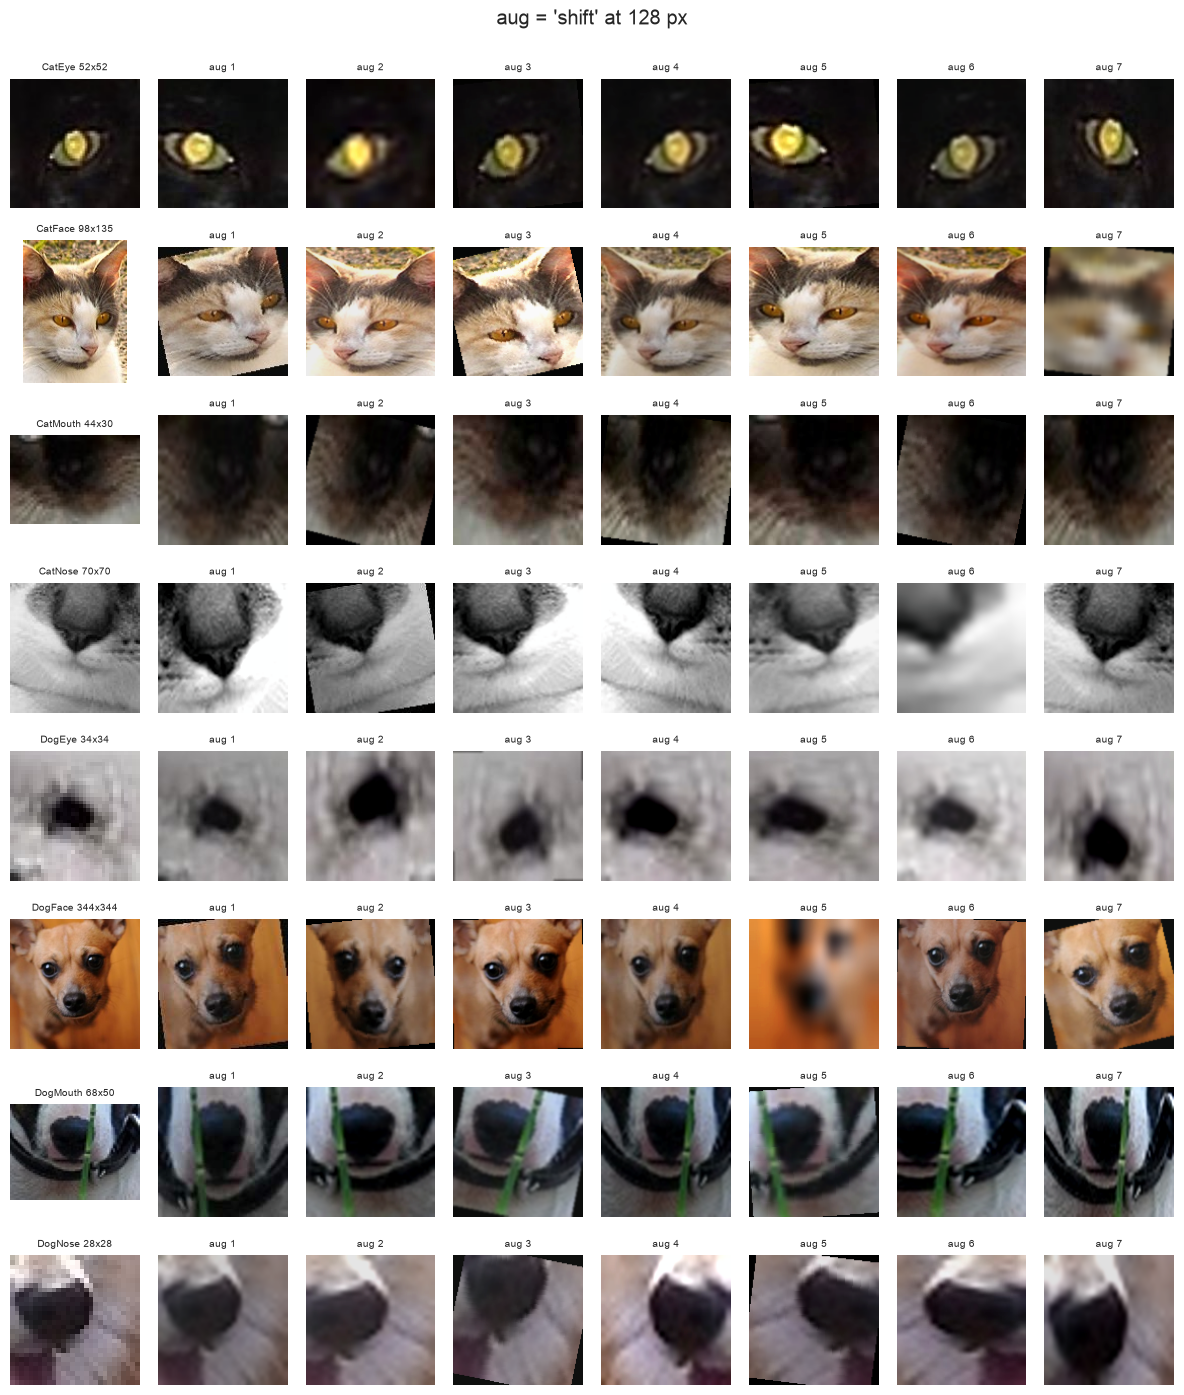

In [14]:
cfg_prev = make_config("convnext_tiny_shift")
mean, std = (0.485, 0.456, 0.406), (0.229, 0.224, 0.225)
examples = meta_tr.groupby("class").sample(1, random_state=SEED).reset_index(drop=True)

for aug in ["none", "plain", "shift"]:
    cfg_prev.aug = aug
    tf = build_train_transform(cfg_prev, mean, std)
    imgs, titles = [], []
    for _, r in examples.iterrows():
        img = Image.open(r["path"]).convert("RGB")
        imgs.append(img)
        titles.append(f"{r['class']} {img.width}x{img.height}")
        for k in range(7):
            imgs.append(Image.fromarray((denormalize(tf(img), mean, std) * 255).astype(np.uint8)))
            titles.append(f"aug {k + 1}")
    show_grid(imgs, titles, ncols=8, size=1.5, suptitle=f"aug = '{aug}' at {cfg_prev.img_size} px", name=f"02_aug_{aug}")

> **Observations (to be written by me):**

## 7. Speed benchmarks and expected training time

* **Loader**: images/s the DataLoader delivers with the `shift` augmentation at 128 px, for several worker counts.
* **Models**: training and inference images/s on random input for each preset (pure model speed).
  Expected epoch time = training images / training speed + 2 × validation images / inference speed
  (validation runs on `val_clean` and `val_shift`).

In [15]:
if BENCHMARK:
    folds_df = pd.read_csv(FOLDS_CSV, dtype={"image_id": str}).merge(meta_tr[["image_id", "path"]], on="image_id")
    folds_df["label"] = folds_df["class"].map({c: i for i, c in enumerate(CLASSES)})
    cfg_b = make_config("convnext_tiny_shift")
    ds = FaceDataset(folds_df, build_train_transform(cfg_b, mean, std))
    loader_rows = []
    for nw in [0, 4, 6, 8]:
        ips = benchmark_loader(make_loader(ds, 128, shuffle=True, num_workers=nw), n_batches=15 if nw else 5)
        loader_rows.append({"num_workers": nw, "images/s": round(ips)})
    display(pd.DataFrame(loader_rows))

,num_workers,images/s
0,0,731
1,4,3490
2,6,4971
3,8,8315


In [16]:
if BENCHMARK:
    n_train = int((folds_df["fold"] != 0).sum())
    n_val = int((folds_df["fold"] == 0).sum())
    bench_rows = []
    for name in ["cnn_shift", "abl_base", "convnext_tiny_shift", "vit_small_shift", "effnet_b0_shift"]:
        cfg_b = make_config(name)
        tr_ips, ev_ips = benchmark_model(cfg_b, batch_size=cfg_b.batch_size, steps=10)
        epoch_min = (n_train / tr_ips + 2 * n_val / ev_ips) / 60
        bench_rows.append({"preset": name, "model": cfg_b.model_name, "img_size": cfg_b.img_size,
                           "train img/s": round(tr_ips), "eval img/s": round(ev_ips),
                           "min / epoch": round(epoch_min, 1), "epochs": cfg_b.epochs,
                           "hours / fold": round(epoch_min * cfg_b.epochs / 60, 2),
                           "hours / 5 folds": round(5 * epoch_min * cfg_b.epochs / 60, 1)})
    bench = pd.DataFrame(bench_rows)
    bench.to_csv(FIG_DIR / "02_benchmark.csv", index=False)
    display(bench)
    print("device:", get_device())

,preset,model,img_size,train img/s,eval img/s,min / epoch,epochs,hours / fold,hours / 5 folds
0,cnn_shift,simple_cnn,96,653,1942,1.5,20,0.51,2.5
1,abl_base,efficientnet_b0.ra_in1k,128,166,531,5.9,6,0.59,3.0
2,convnext_tiny_shift,convnext_tiny.fb_in22k_ft_in1k,128,69,354,13.5,10,2.24,11.2
3,vit_small_shift,vit_small_patch16_224.augreg_in21k_ft_in1k,128,173,606,5.6,10,0.94,4.7
4,effnet_b0_shift,efficientnet_b0.ra_in1k,128,175,548,5.6,12,1.13,5.6


device: mps


> **Observations (to be written by me):**